Train shape: (171630, 768), Test shape: (69841, 768)
{'rmse': 1.106819013177731, 'mae': 0.26718862960494877, 'r2': 0.008822760569761723}


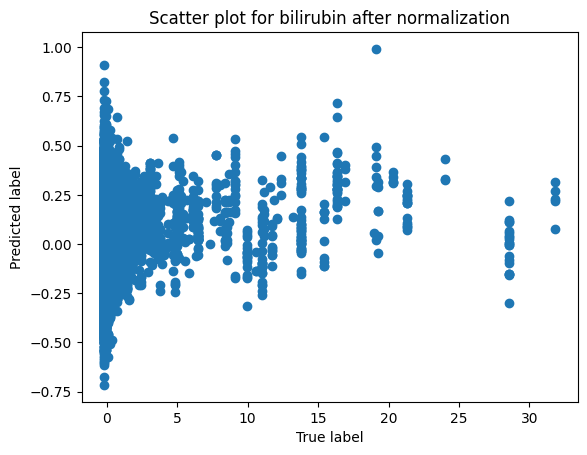

Train shape: (284980, 768), Test shape: (117828, 768)
{'rmse': 0.9070101395255694, 'mae': 0.44500555786062607, 'r2': 0.30112517284411333}


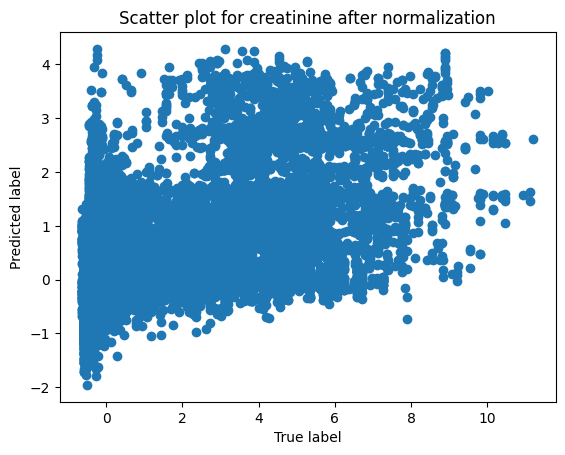

Train shape: (271213, 768), Test shape: (110893, 768)
{'rmse': 1.0101915295079793, 'mae': 0.6995116517321338, 'r2': 0.08258716981285164}


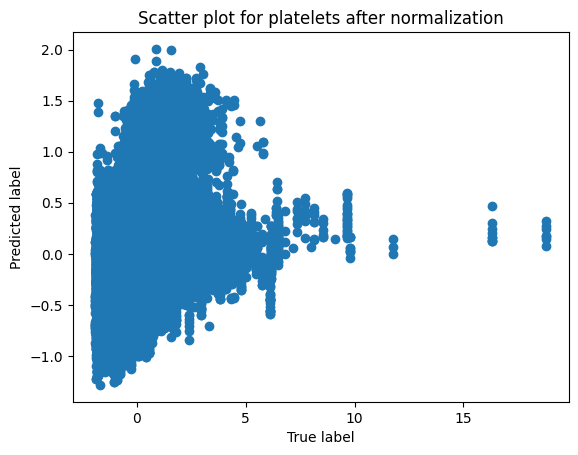

In [1]:
# normalization
import sklearn
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# from sklearn.linear_model import RidgeCV



for task in ["bilirubin","creatinine","platelets"]:
    features_dir = Path(f"/data/results/zj2398/femr/cumc_0.1/regression_2_5_months/tpp/results/{task}/tpp/features_with_label")
    train_data = pd.read_parquet(features_dir/"train.parquet")
    test_data = pd.read_parquet(features_dir/"test.parquet")

    X_train = np.vstack(train_data["features"].to_numpy())
    X_test  = np.vstack(test_data["features"].to_numpy())

    # y: normalize using TRAIN stats
    y_train_raw = train_data["numerical_value"].astype(float).to_numpy()
    y_test_raw  = test_data["numerical_value"].astype(float).to_numpy()

    mu = y_train_raw.mean()
    sigma = max(y_train_raw.std(ddof=0), 1e-12)
    y_train = (y_train_raw - mu) / sigma
    y_test  = (y_test_raw  - mu) / sigma


    print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

    # y_train = normalize(train_data["numerical_value"].astype(float))
    # y_test = normalize(test_data["numerical_value"].astype(float))

    model = Pipeline([
        ("scaler", StandardScaler(with_mean=True, with_std=True)),
        ("ridge", LinearRegression()),
    ])
    # print(X_train)
    # print(y_train)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
    mae = float(mean_absolute_error(y_test, y_pred))
    r2 = float(r2_score(y_test, y_pred))
    metrics = {
        "rmse": rmse,
        "mae": mae,
        "r2": r2,
    }
    print(metrics)
    plt.scatter(y_test,y_pred)
    plt.xlabel("True label")
    plt.ylabel("Predicted label")
    plt.title(f"Scatter plot for {task} after normalization")
    plt.show()

Train shape: (171630, 768), Test shape: (69841, 768)
{'rmse': 1.385545670190349, 'mae': 0.8413139465547564, 'r2': -0.002886668037292761}


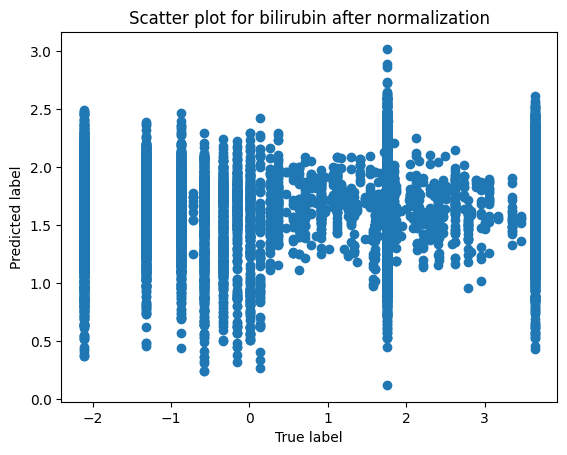

Train shape: (284980, 768), Test shape: (117828, 768)
{'rmse': 1.3373666483717523, 'mae': 0.819044286410306, 'r2': 0.023883745176802806}


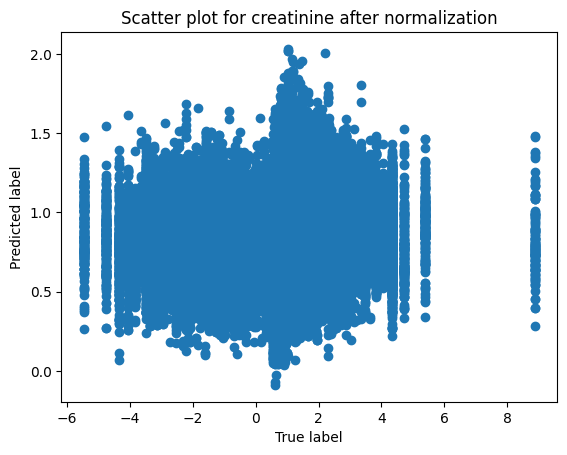

Train shape: (271213, 768), Test shape: (110893, 768)
{'rmse': 1.384646359308865, 'mae': 0.9936308897890147, 'r2': 0.0034253105503687653}


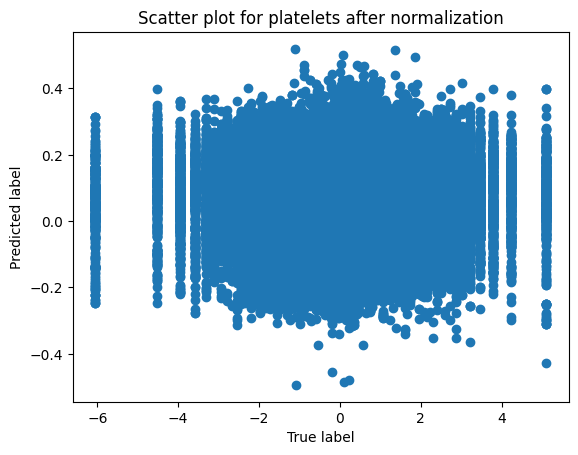

In [6]:
# normalization + log transform
import sklearn
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# from sklearn.linear_model import RidgeCV



for task in ["bilirubin","creatinine","platelets"]:
    features_dir = Path(f"/data/results/zj2398/femr/cumc_0.1/regression_2_5_months/tpp/results/{task}/tpp/features_with_label")
    train_data = pd.read_parquet(features_dir/"train.parquet")
    test_data = pd.read_parquet(features_dir/"test.parquet")

    X_train = np.vstack(train_data["features"].to_numpy())
    X_test  = np.vstack(test_data["features"].to_numpy())

    # y: normalize using TRAIN stats
    y_train_raw = train_data["numerical_value"].astype(float).to_numpy()
    y_test_raw  = test_data["numerical_value"].astype(float).to_numpy()

    mu = y_train_raw.mean()
    sigma = max(y_train_raw.std(ddof=0), 1e-12)

    # log transform + normalization
    y_train = (y_train_raw - mu) / sigma
    y_test  = (y_test_raw  - mu) / sigma

    y_train = np.sign(y_train) * np.log(np.abs(y_train))
    y_test  = np.sign(y_test)  * np.log(np.abs(y_test))

    print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

    # y_train = normalize(train_data["numerical_value"].astype(float))
    # y_test = normalize(test_data["numerical_value"].astype(float))

    model = Pipeline([
        ("scaler", StandardScaler(with_mean=True, with_std=True)),
        ("ridge", LinearRegression()),
    ])
    # print(X_train)
    # print(y_train)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
    mae = float(mean_absolute_error(y_test, y_pred))
    r2 = float(r2_score(y_test, y_pred))
    metrics = {
        "rmse": rmse,
        "mae": mae,
        "r2": r2,
    }
    print(metrics)
    plt.scatter(y_test,y_pred)
    plt.xlabel("True label")
    plt.ylabel("Predicted label")
    plt.title(f"Scatter plot for {task} after normalization")
    plt.show()